# 04 · Receita: quanto o ARC Raiders faturou até hoje

Etapa 7 do projeto.

**O que a Nexon divulga** [O]
- Unidades por trimestre: **10,9 mi** (Q4/25), **4,6 mi** (Q1/26), **0,8 mi** (Q2/26): 16,3 mi no total.
- Receita reconhecida: **¥18,3 bi** em Q2/26 e **¥88 bi** acumulados até jun/2026 (≈ US$ 559 mi).
- As vendas na Steam (**~60% das unidades**) têm a receita **diferida**: ¥27,7 bi foram adiados em Q4/25 e reconhecidos ao longo de 2026. Por isso a receita oficial de cada trimestre não corresponde às vendas daquele trimestre.

**O que não é divulgado:** receita trimestral antes de Q2/26 e a divisão entre vendas do jogo e loja interna (cosméticos, passes, Raider Tokens).

**Método:** um modelo de Monte Carlo (20 mil simulações) em **base econômica**, isto é, antes do diferimento contábil:

| Premissa | Faixa | Por quê |
|---|---|---|
| Receita líquida por unidade | US$ 21–32 | Sensor Tower estima US$ 30,6 brutos por unidade na Steam (com preços regionais e descontos); 21 = líquido dos 30% das lojas |
| Saldo ainda diferido em jun/26 | ¥5–20 bi | sobra dos ¥27,7 bi de Q4 + novas vendas diferidas em 2026 |
| Câmbio | ¥154–161 por US$ | faixa do período; Q2 = 160,7 no release |
| Unidades no 3º tri | ±30% | estimadas pela razão de análises Q3/Q2 |

Mensalmente, as unidades de cada trimestre são repartidas pelo número de análises do mês (método validado na Etapa 4, erro de 1%), e a loja interna é distribuída pelas horas jogadas (premissa de gasto constante por hora jogada [P]).

In [1]:
import json, sys
from pathlib import Path
from IPython.display import Image

sys.path.insert(0, str(Path.cwd().parent / "src"))
from analysis import revenue

revenue.main()
metrics = json.loads(Path("../reports/metrics_receita.json").read_text(encoding="utf-8"))

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


figura: 10a_receita_acumulada.png
figura: 10b_receita_mensal_composicao.png
figura: 10c_sensibilidade_premissas.png
{
 "receita_economica_ate_jun26_usd_mi": [
  599.8420069507349,
  638.4971382236474,
  677.0057928426261
 ],
 "vendas_jogo_ate_jun26_usd_mi": [
  360.2827741604213,
  432.00342848777825,
  503.78944901530815
 ],
 "loja_interna_ate_jun26_usd_mi": [
  127.5222793808377,
  206.39041934346247,
  286.67109894489244
 ],
 "loja_interna_pct_da_receita": [
  20.479201337401747,
  32.390303488405806,
  43.79981477261911
 ],
 "q3_26_unidades_mi": [
  0.26283435585226395,
  0.34643839675942023,
  0.4284575029196443
 ],
 "q3_26_receita_usd_mi": [
  17.661581367204896,
  21.90072737942311,
  25.893224469543362
 ],
 "q3_26_loja_interna_usd_mi": [
  7.823520452487281,
  12.662098535023834,
  17.587336241335922
 ],
 "receita_economica_ate_set26_usd_mi": [
  619.0877214936864,
  660.2650702328476,
  701.4503861394556
 ],
 "unidades_ate_set26_mi": [
  16.562834355852264,
  16.64643839675942

## 1. A curva da receita

**Receita econômica estimada até 25/09/2026: US$ 660 mi** (faixa de 80%: 619–701). A receita reconhecida oficialmente fica abaixo porque parte das vendas na Steam ainda está diferida: US$ 442 mi em mar/2026 e US$ 559 mi em jun/2026.

A curva mostra o formato típico de um jogo pago: **73% da receita veio nos 4 primeiros meses** (out/25–jan/26), e desde abril o acréscimo mensal caiu para a casa de US$ 10–20 mi.

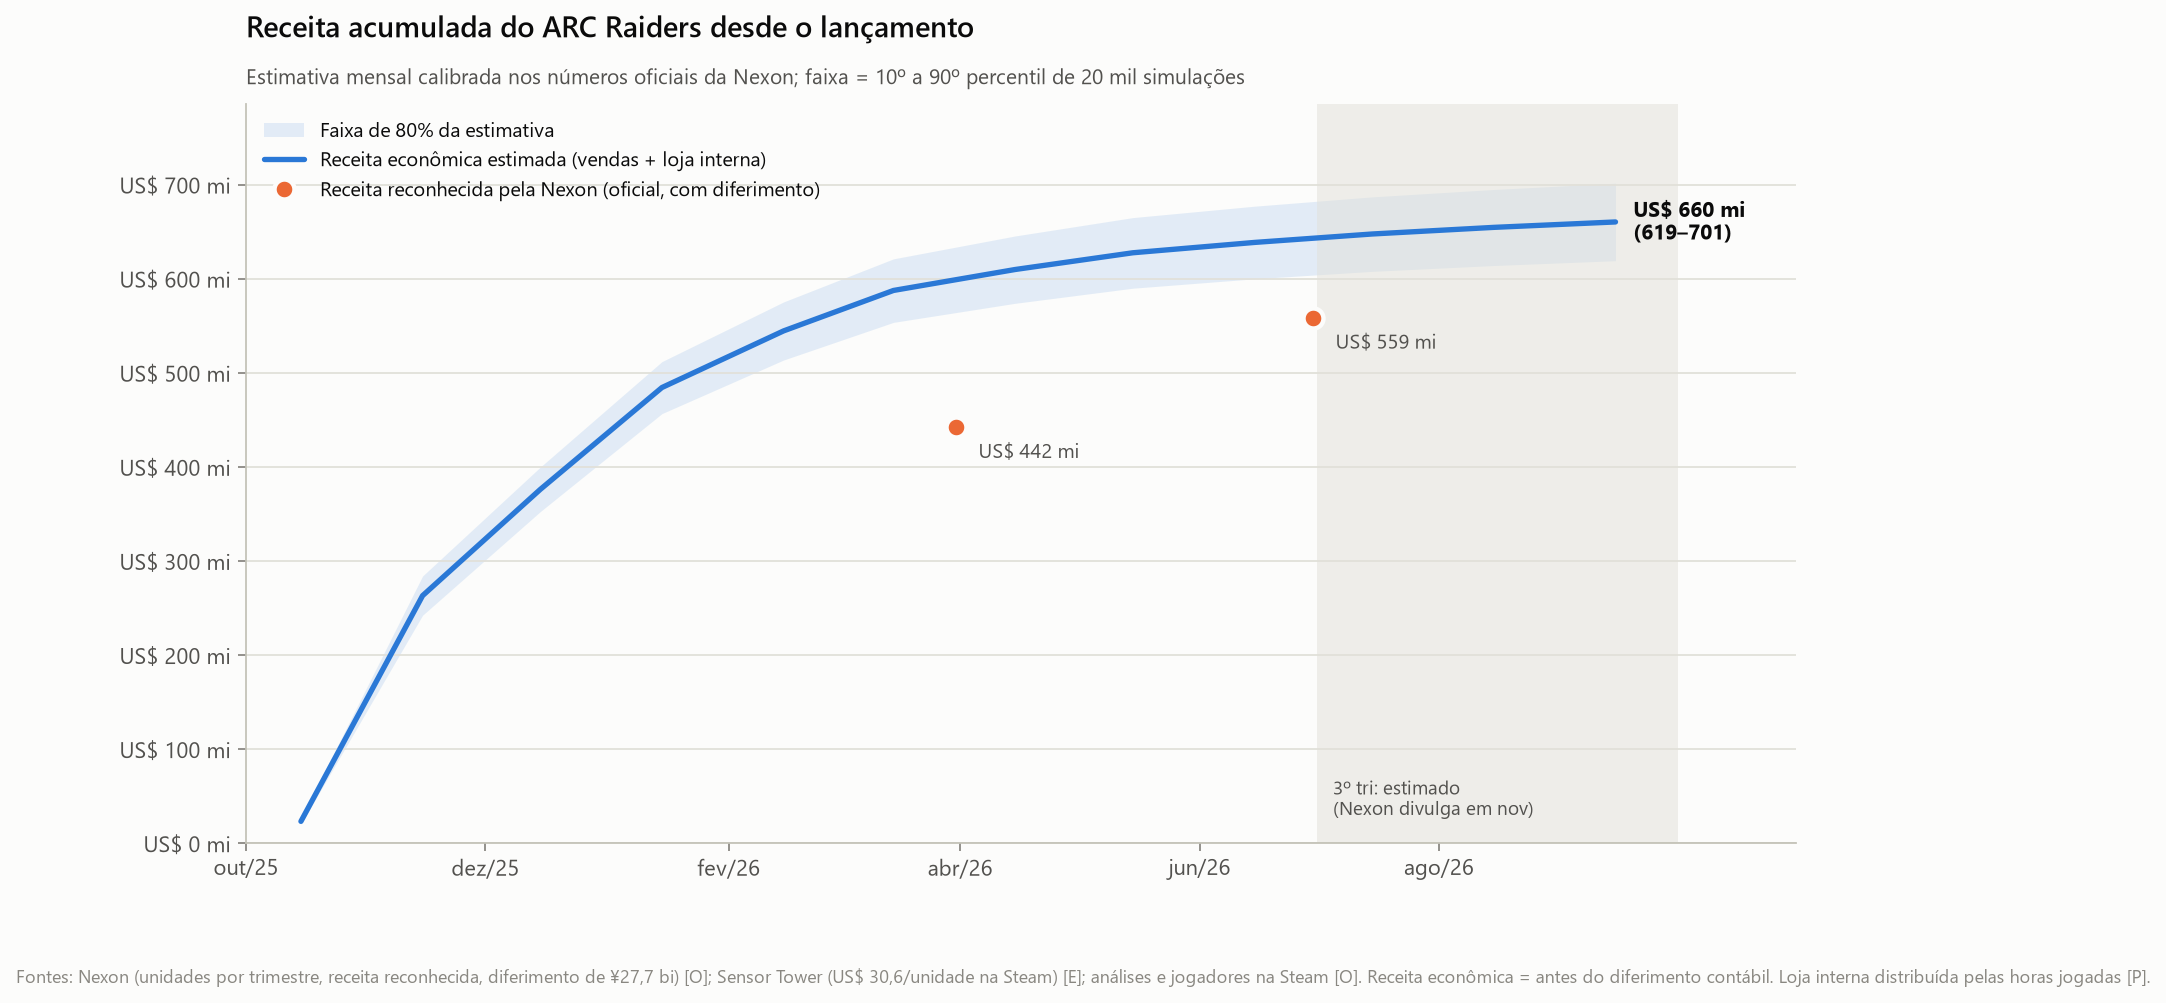

In [2]:
Image("../reports/figures/10a_receita_acumulada.png")

## 2. Vendas do jogo x loja interna

| Até jun/2026 | Mediana | Faixa de 80% |
|---|---|---|
| Receita econômica | US$ 638 mi | 600–677 |
| Vendas do jogo | US$ 432 mi | 360–504 |
| Loja interna | **US$ 206 mi** | 128–287 |
| Loja interna, % da receita | **32%** | 20–44% |
| Receita por unidade vendida | US$ 39 | 37–42 |

Até março, as vendas do jogo dominaram. **A partir de abril, a loja interna passou a responder pela maior parte da receita mensal**, mas num patamar baixo, porque acompanha a base de jogadores, que caiu 92%.

**3º trimestre (jul–set/2026), estimado:** 0,35 mi de unidades e **US$ 22 mi** de receita econômica (18–26), dos quais ~US$ 13 mi da loja. A receita que a Nexon vai *reconhecer* em novembro deve ser maior, porque inclui a liberação do saldo diferido da Steam.

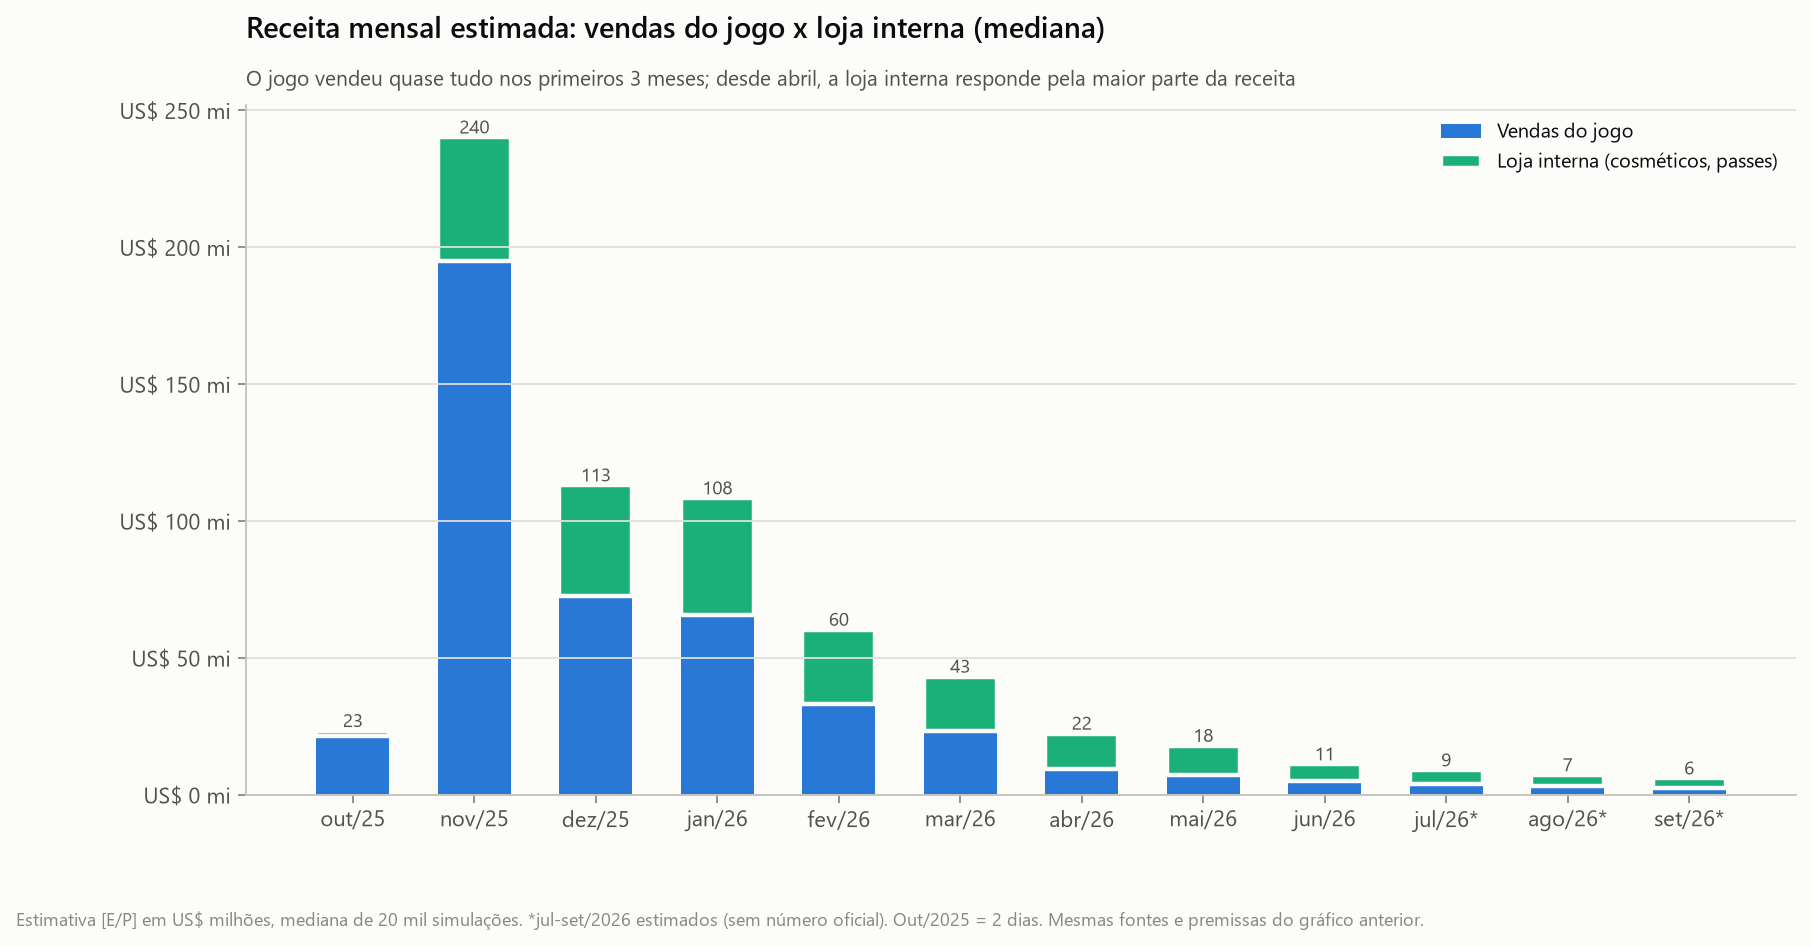

In [3]:
Image("../reports/figures/10b_receita_mensal_composicao.png")

## 3. O que mais pesa na estimativa

A maior incerteza é contábil: não sabemos se a Nexon registra a venda bruta ou líquida da taxa das lojas (30%). Essa premissa sozinha move a loja interna em ±US$ 80 mi. O saldo diferido vem em seguida (±US$ 40 mi); o câmbio pesa pouco. O **total** (US$ 600–677 mi até jun) é bem mais firme que a divisão entre vendas e loja.

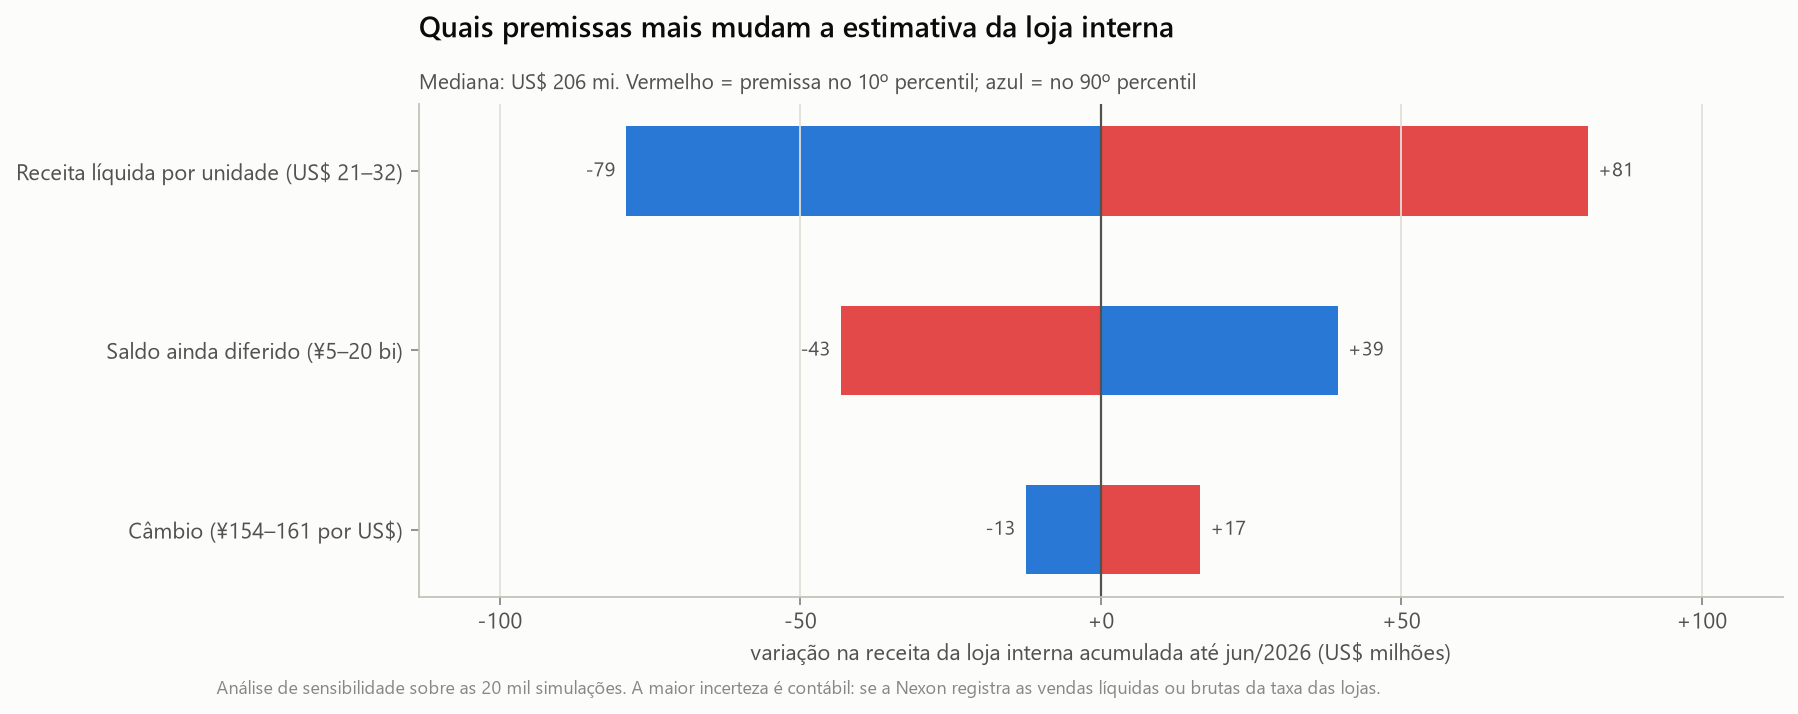

In [4]:
Image("../reports/figures/10c_sensibilidade_premissas.png")

## 4. Contexto de mercado [G]

| Fonte | Mercado | 2025 | Crescimento |
|---|---|---|---|
| Fortune Business Insights | Jogos de tiro (inclui mobile) | US$ 82,0 bi | 9,1% ao ano até 2034 |
| Cognitive Market Research | FPS | US$ 12,3 bi | 6,5% ao ano até 2033 |

As definições são muito diferentes (uma inclui mobile e battle royales gratuitos), então usamos as duas só como ordem de grandeza: os ~US$ 640 mi do ARC Raiders no primeiro ano equivalem a **~5% do mercado de FPS** medido pela Cognitive, ou **<1% do mercado amplo de tiro**.

## Síntese

1. **O ARC Raiders já se pagou várias vezes**: ~US$ 660 mi em 11 meses, com 16,6 mi de unidades estimadas até set/2026.
2. **A receita é de jogo pago, não de serviço**: ~2/3 vieram da venda do jogo, concentrada nos 3 primeiros meses.
3. **A loja interna existe (~1/3), mas depende de jogadores ativos**: caiu junto com a base, para ~US$ 4 mi/mês no 3º tri.
4. Para 2027, a pergunta de negócio muda: **não é quanto o jogo já fez, mas quanto a loja e novas vendas podem render com uma base recuperada** (Etapas 8 e 9).